# Introduction

Music Streaming platforms like Spotify contains a huge collection of songs across different artists nd genres. Understanding the characteristics of these tracks can help us explore patterns in music popularity.

In this project, I will analyze a Spotify tracks dataset containing track details, artists, genres, popularity scores, and audio features such as danceability, energy, and tempo. The goal is to explore the dataset, identify meaningful patterns, and generate insights that could h elp a music-streaming platform better understand its music catalog.

## Business Use Case

Music streaming platforms like Spotify need to understand what makes their music catalog popular and engaging for listeners.

Analyzing track popularity, music genres, and audio features can help identify patterns in listener preferences. These insights may support better music recommendations, playlist creation, and music catalog management.

In this project, I will use data analysis to explore these patterns and provide data-driven recommendations based on the findings.

## Project Objectives

The main objectives of this project are:

1. Understand the structure and quality of the Spotify tracks dataset.
2. Identify and handle missing values, duplicate records, and data inconsistencies.
3. Explore the distribution of track popularity and audio features.
4. Analyze popularity patterns across different music genres.
5. Examine relationships between audio features and track popularity.
6. Answer business questions using data analysis and visualization.
7. Present key findings and provide practical business recommendations.

### Import Libraries

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

import warnings 
warnings.filterwarnings("ignore")

## Dataset Information

The Spotify Tracks Dataset contains information about music tracks, including track names, artists, genres, popularity scores, and audio characteristics.

Before beginning the analysis, it is important to understand the dataset's structure, the meaning of its columns, and the type of information available.

### Load Dataset

In [2]:
data = pd.read_csv("dataset.csv")

In [3]:
data.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [4]:
data.shape

(114000, 21)

In [5]:
data.columns

Index(['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name',
       'popularity', 'duration_ms', 'explicit', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'track_genre'],
      dtype='object')

### Understand the Data

Before cleaning or analyzing the dataset, it is important to understand its structure, data types, statistical properties, and overall quality.


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [7]:
data.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


### Checking the Categorical Columns

In [8]:
data.describe(include = "object")

,track_id,artists,album_name,track_name,track_genre
count,114000,113999,113999,113999,114000
unique,89741,31437,46589,73608,114
top,6S3JlDAGk3uu3NtZbPnuhS,The Beatles,Alternative Christmas 2022,Run Rudolph Run,acoustic
freq,9,279,195,151,1000


### Check missing values

In [9]:
missing_values = data.isnull().sum()
missing_values

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [10]:
missing_percentage = (data.isnull().sum() / len(data) ) * 100
print(missing_percentage.sort_values(ascending = False))

artists             0.000877
album_name          0.000877
track_name          0.000877
Unnamed: 0          0.000000
mode                0.000000
time_signature      0.000000
tempo               0.000000
valence             0.000000
liveness            0.000000
instrumentalness    0.000000
acousticness        0.000000
speechiness         0.000000
key                 0.000000
loudness            0.000000
track_id            0.000000
energy              0.000000
danceability        0.000000
explicit            0.000000
duration_ms         0.000000
popularity          0.000000
track_genre         0.000000
dtype: float64


### Checking duplicate rows

In [11]:
duplicate_count = data.duplicated().sum()
duplicate_count

np.int64(0)

### Checking duplicate track IDs

In [12]:
duplicate_track_ids = data["track_id"].duplicated().sum()
duplicate_track_ids

np.int64(24259)

In [13]:
repeated_tracks = data[data["track_id"].duplicated(keep = False)]
repeated_tracks

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
5,5,01MVOl9KtVTNfFiBU9I7dc,Tyrone Wells,Days I Will Remember,Days I Will Remember,58,214240,False,0.688,0.4810,...,-8.807,1,0.1050,0.2890,0.000000,0.1890,0.6660,98.017,4,acoustic
6,6,6Vc5wAMmXdKIAM7WUoEb7N,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,229400,False,0.407,0.1470,...,-8.822,1,0.0355,0.8570,0.000003,0.0913,0.0765,141.284,3,acoustic
7,7,1EzrEOXmMH3G43AXT1y7pA,Jason Mraz,We Sing. We Dance. We Steal Things.,I'm Yours,80,242946,False,0.703,0.4440,...,-9.331,1,0.0417,0.5590,0.000000,0.0973,0.7120,150.960,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113572,113572,1saXUvvFlAQaefZUFVmhCn,Bethel Music;Paul McClure,We Will Not Be Shaken (Live),Jesus We Love You - Live,53,415079,False,0.253,0.3590,...,-8.482,1,0.0317,0.3100,0.000006,0.3590,0.1150,115.348,3,world-music
113605,113605,1Q5jFp1g2Ns4gBsHRpcqhu,Bethel Music;Jenn Johnson;Michaela Gentile,Simple,In The Ordinary - Spontaneous,50,174971,False,0.490,0.2310,...,-13.968,1,0.0265,0.6070,0.000000,0.0859,0.0904,103.958,4,world-music
113617,113617,71dLJx3qHOTQMTvvoE2dmd,Bethel Music;Amanda Cook,Peace,King of My Heart,48,330840,False,0.515,0.0736,...,-15.492,1,0.0310,0.9750,0.000261,0.0820,0.0684,109.964,4,world-music
113619,113619,6OG5TBCmuTOuWCzSGsETrE,Bethel Music;Brian Johnson;Jenn Johnson,Simple,Simple,48,351236,False,0.624,0.1240,...,-11.191,1,0.0280,0.9170,0.000000,0.1200,0.2060,78.014,4,world-music


In [14]:
len(repeated_tracks)

40900

In [15]:
# Display few repeated track records

repeated_tracks[["track_id","track_name","artists", "track_genre"]].head(10)

,track_id,track_name,artists,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Comedy,Gen Hoshino,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ghost - Acoustic,Ben Woodward,acoustic
5,01MVOl9KtVTNfFiBU9I7dc,Days I Will Remember,Tyrone Wells,acoustic
6,6Vc5wAMmXdKIAM7WUoEb7N,Say Something,A Great Big World;Christina Aguilera,acoustic
7,1EzrEOXmMH3G43AXT1y7pA,I'm Yours,Jason Mraz,acoustic
9,7k9GuJYLp2AzqokyEdwEw2,Hunger,Ross Copperman,acoustic
12,4ptDJbJl35d7gQfeNteBwp,Solo,Dan Berk,acoustic
13,0X9MxHR1rTkEHDjp95F2OO,Bad Liar,Anna Hamilton,acoustic
16,6xKeQgzfjixSUld14qUezm,ily (i love you baby),Andrew Foy;Renee Foy,acoustic
17,4Yo0igmcoNyat1secaH0OD,At My Worst,Andrew Foy;Renee Foy,acoustic


### Comparing Repeated Track IDs Across Genres

Repeated track IDs may occur for different reasons. I will examine individual records to check whether the same track ID is associated with different genres or metadata. This will help me decide whether these records should be retained for genre analysis or require further investigation.

In [16]:
track_id_counts = data["track_id"].value_counts()
track_id_counts

track_id
6S3JlDAGk3uu3NtZbPnuhS    9
2Ey6v4Sekh3Z0RUSISRosD    8
2kkvB3RNRzwjFdGhaUA0tz    8
5ZsAhuQ24mWHiduaxJqnhW    7
08kTa3SL9sV6Iy8KLKtGql    7
                         ..
0kJ7eKX6aWl8X1W5Xrosn6    1
4bYH5445Bn2w9UiGM0NxQw    1
1T5C6ENvpM3IiYeezsK9uI    1
34SatKRJgtXfL0bcgk7HMA    1
2hETkH7cOfqmz3LqZDHZf5    1
Name: count, Length: 89741, dtype: int64

In [17]:
most_repeated_id = track_id_counts.index[0]
print("Track ID:", most_repeated_id)
print("Number of occurrences:", track_id_counts.iloc[0])

Track ID: 6S3JlDAGk3uu3NtZbPnuhS
Number of occurrences: 9


In [18]:
# Displaying the all records of that track id 
data.loc[data["track_id"] == most_repeated_id, ["track_id", "track_name", "artists", "track_genre"]]

,track_id,track_name,artists,track_genre
8315,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,blues
19759,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,country
34728,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,folk
62226,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,j-pop
63087,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,j-rock
82064,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,power-pop
84129,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,psych-rock
99727,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,singer-songwriter
102732,6S3JlDAGk3uu3NtZbPnuhS,Baby Blue - Remastered 2010,Badfinger,songwriter


The dataset contains the same track under multiple genre categories. These rows are not exact duplicates because the track_genre value differs.

In [19]:
data.dtypes

Unnamed: 0            int64
track_id             object
artists              object
album_name           object
track_name           object
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre          object
dtype: object

In [20]:
num_columns = data.select_dtypes(include = "number").columns 
cat_columns = data.select_dtypes(include = ["object","bool"]).columns
list(num_columns)

['Unnamed: 0',
 'popularity',
 'duration_ms',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'time_signature']

In [21]:
list(cat_columns)

['track_id', 'artists', 'album_name', 'track_name', 'explicit', 'track_genre']

### Checking Invalid Values

After examining the data types, I will validate important numerical columns to identify values outside their expected ranges. This step helps me to detect potential data quality issues before performing exploratory data analysis.

In [22]:
# Checking the minimum and maximum popularity values
print("Minimum popularity" , data["popularity"].min())
print("Maximum popularity" , data["popularity"].max())

Minimum popularity 0
Maximum popularity 100


In [23]:
# Checking the minimum and maximum values of audio features
audio_features = ["danceability","energy","speechiness","acousticness","instrumentalness","liveness","valence"]
data[audio_features].agg(["min","max"]).T

,min,max
danceability,0.0,0.985
energy,0.0,1.000
speechiness,0.0,0.965
acousticness,0.0,0.996
instrumentalness,0.0,1.000
liveness,0.0,1.000
valence,0.0,0.995


In [24]:
# Checking track duration in milliseconds
print("Minimum duration:", data["duration_ms"].min())
print("Maximum duration:", data["duration_ms"].max())
print("No.of Zero duaration tracks:", (data["duration_ms"] == 0).sum())

Minimum duration: 0
Maximum duration: 5237295
No.of Zero duaration tracks: 1


The duration check identified one track with a duration of zero milliseconds. Since a zero-duration value may indicate incomplete or invalid track information.

In [25]:
data.loc[ data["duration_ms"] == 0, ["track_id", "track_name", "artists", "album_name","duration_ms", "popularity", "track_genre"]]

,track_id,track_name,artists,album_name,duration_ms,popularity,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,k-pop


This record has no useful information. Since both the duration and identifying fields are missing, we can remove this particular row.

In [26]:
# Converting the longest track duration from milliseconds to minutes
max_duration_minutes = data["duration_ms"].max() / 60000
print("Longest Tracking Duration:", round(max_duration_minutes,2), "minutes")

Longest Tracking Duration: 87.29 minutes


The longest track is 87.29 minutes, this could be the long recording..

### Conclusion from Data Quality Checks:

The initial data quality checks identified one record with a zero duration, zero popularity, and missing track name, artist, and album information. Since this record lacks essential track details and cannot provide meaningful information for track-level analysis, it will be removed during the data cleaning.

The dataset also contains repeated track id's across different genre labels. These records will be retained because the genre differences may be important for genre-based analysis.

The longest track duration is approximately 87.29 minutes.

## Data Cleaning

In [27]:
# Creating a copy of the original dataset
clean_data = data.copy()
print("Rows before Cleaning:",len(clean_data))


Rows before Cleaning: 114000


### Removing the invalid zero-duration record

In [28]:
clean_data = clean_data[clean_data["duration_ms"] > 0]
len(clean_data)

113999

In [29]:
print("Zero_duration records remaining:", (clean_data["duration_ms"] == 0).sum())

Zero_duration records remaining: 0


### Handling Missing Values

Missing values can affect data analysis and may lead to incomplete or misleading results.

In [30]:
missing_values = clean_data.isnull().sum()
print(missing_values[missing_values > 0])

Series([], dtype: int64)


There are no missing values in the clean_data

### Checking Unnecessary Columns

In [31]:
print(clean_data["Unnamed: 0"].head(10))
print(clean_data["Unnamed: 0"].nunique())
print(len(clean_data))

0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
Name: Unnamed: 0, dtype: int64
113999
113999


Every row has a unique value in this column, and it acts as an exported row index rather than a meaningful music feature, so we can remove it.

Pandas already maintains its own row index, so this extra column is not needed for our analysis.

In [32]:
# Removing the unnecessary row-index column
clean_data = clean_data.drop(columns = ["Unnamed: 0"])

In [33]:
clean_data.shape

(113999, 20)

In [34]:
clean_data.columns.tolist()

['track_id',
 'artists',
 'album_name',
 'track_name',
 'popularity',
 'duration_ms',
 'explicit',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'time_signature',
 'track_genre']

### Check text formatting

### Standardizing Text Columns

Text columns may contain unnecessary spaces at the beginning or end of values. These spaces can cause identical artist names, track names, or genres to be treated as different values during grouping and analysis.

In [35]:
text_columns = clean_data.select_dtypes(include = "object").columns
print(text_columns.tolist())

['track_id', 'artists', 'album_name', 'track_name', 'track_genre']


I have identified five text columns in the dataset. I will remove leading and trailing whitespace from these columns to maintain consistent text values.

In [36]:
# Removing leading and trailing spaces from text columns
for column in text_columns:
    clean_data[column] = clean_data[column].str.strip()

Text cleaning completed..

### Converting Track Duration into Minutes
Currently, the duration_ms column stores track duration in milliseconds. I will convert the duration into minutes by dividing the values by 60,000. Because minutes are easier to understand when analyzing song lengths and creating visualizations.

In [37]:
# Converting track duration from milliseconds to minutes
clean_data["duration_minutes"] = clean_data["duration_ms"]/60000
clean_data[["track_name", "duration_ms", "duration_minutes"]].head(10)   # original and converted duration

,track_name,duration_ms,duration_minutes
0,Comedy,230666,3.844433
1,Ghost - Acoustic,149610,2.493500
2,To Begin Again,210826,3.513767
3,Can't Help Falling In Love,201933,3.365550
4,Hold On,198853,3.314217
5,Days I Will Remember,214240,3.570667
6,Say Something,229400,3.823333
7,I'm Yours,242946,4.049100
8,Lucky,189613,3.160217
9,Hunger,205594,3.426567


We are keeping duration_ms because the original data can still be useful for precise calculations.

In [38]:
clean_data["duration_minutes"].describe()

count    113999.000000
mean          3.800519
std           1.788268
min           0.143100
25%           2.901100
50%           3.548433
75%           4.358433
max          87.288250
Name: duration_minutes, dtype: float64

In [39]:

# Count completely duplicated rows

duplicate_rows = clean_data.duplicated().sum()
duplicate_rows

np.int64(450)

There are 450 completely duplicated rows..

In [40]:
repeated_track_ids = clean_data["track_id"].duplicated().sum()
repeated_track_ids

np.int64(24259)

In [41]:
duplicate_records = clean_data[clean_data.duplicated(keep = False)]
len(duplicate_records)

894

In [42]:
duplicate_records[["track_id", "track_name", "artists", "track_genre"]].head(10)

,track_id,track_name,artists,track_genre
1874,0CDucx9lKxuCZplLXUz0iX,Song for Rollins,Buena Onda Reggae Club,afrobeat
1925,0CDucx9lKxuCZplLXUz0iX,Song for Rollins,Buena Onda Reggae Club,afrobeat
2109,2aibwv5hGXSgw7Yru8IYTO,Snow (Hey Oh),Red Hot Chili Peppers,alt-rock
2155,2aibwv5hGXSgw7Yru8IYTO,Snow (Hey Oh),Red Hot Chili Peppers,alt-rock
3683,7mULVp0DJrI2Nd6GesLvxn,Love Will Tear Us Apart,Joy Division,alternative
3738,7mULVp0DJrI2Nd6GesLvxn,Love Will Tear Us Apart,Joy Division,alternative
4598,6d3RIvHfVkoOtW1WHXmbX3,Margot,Little Symphony,ambient
4648,6d3RIvHfVkoOtW1WHXmbX3,Margot,Little Symphony,ambient
5721,481beimUiUnMUzSbOAFcUT,突破口,SUPER BEAVER,anime
5769,481beimUiUnMUzSbOAFcUT,突破口,SUPER BEAVER,anime


In [43]:
# Counting the number of unique genres associated with each track ID
genres_per_track = clean_data.groupby("track_id")["track_genre"].nunique()

In [44]:
# Finding track IDs that appear under more than one genre
multiple_genre_ids = genres_per_track[genres_per_track > 1]

In [45]:
print("Track IDs associated with multiple genres:", len(multiple_genre_ids))
print("Maximum number of genres for one track:", genres_per_track.max())

Track IDs associated with multiple genres: 16299
Maximum number of genres for one track: 9


It shows that 16,299 track IDs are associated with more than one genre and One track ID appears under as many as 9 genres.

In this dataset, the same track can appear under multiple genre labels. I will compare the track name, artist, album, and genre to understand these repetitions. A repeated track ID does not always mean that a record is incorrect.

In [46]:
sample_track_id = multiple_genre_ids.index[0]
clean_data.loc[clean_data["track_id"] == sample_track_id, ["track_id", "track_name", "artists", "album_name", "track_genre"]].sort_values("track_genre")

,track_id,track_name,artists,album_name,track_genre
15028,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,New RnB,chill
103211,001APMDOl3qtx1526T11n1,Better,Pink Sweat$;Kirby,New RnB,soul


In [47]:
# Count unique track names and artists for each track ID
track_metadata_check = clean_data.groupby("track_id").agg(
    unique_track_names=("track_name", "nunique"),
    unique_artists=("artists", "nunique"),
    unique_albums=("album_name", "nunique"),
    unique_genres=("track_genre", "nunique")
)
track_metadata_check

,unique_track_names,unique_artists,unique_albums,unique_genres
track_id,,,,
0000vdREvCVMxbQTkS888c,1,1,1,1
000CC8EParg64OmTxVnZ0p,1,1,1,1
000Iz0K615UepwSJ5z2RE5,1,1,1,1
000RDCYioLteXcutOjeweY,1,1,1,1
000qpdoc97IMTBvF8gwcpy,1,1,1,1
...,...,...,...,...
7zxHiMmVLt4LGWpOMqOpUh,1,1,1,1
7zxpdh3EqMq2JCkOI0EqcG,1,1,1,1
7zyYmIdjqqiX6kLryb7QBx,1,1,1,1


In [48]:
# Find track IDs with conflicting names, artists, or albums
conflicting_tracks = track_metadata_check[
    (track_metadata_check["unique_track_names"] > 1) |
    (track_metadata_check["unique_artists"] > 1) |
    (track_metadata_check["unique_albums"] > 1)
]

print("Track IDs with conflicting metadata:", len(conflicting_tracks))

conflicting_tracks.head(10)

Track IDs with conflicting metadata: 0


,unique_track_names,unique_artists,unique_albums,unique_genres
track_id,,,,


From the Output , it confirms that the repeated track IDs have consistent track names, artists, and album names. This means we do not have to remove records just because their track IDs repeat.

### Removing Exact Duplicate Records

In [49]:
rows_before = len(clean_data)
clean_data = clean_data.drop_duplicates()
rows_after = len(clean_data)
print("Rows before removing duplicates:", rows_before)
print("Rows after removing duplicates:", rows_after)
print("Duplicate rows removed:", rows_before - rows_after)

Rows before removing duplicates: 113999
Rows after removing duplicates: 113549
Duplicate rows removed: 450


In [50]:
print("Remaining exact duplicate rows:", clean_data.duplicated().sum())

Remaining exact duplicate rows: 0


### Overall Conclusion of Data Cleaning
The data cleaning process was performed to improve the quality and reliability of the Spotify tracks dataset.

Initially, the dataset contained 113,999 rows and 21 columns. During the cleaning process, 450 exact duplicate records were identified and removed, leaving 113,549 rows and 21 columns. After cleaning, no missing values or exact duplicate rows remained.

The numerical columns were examined using descriptive statistics to understand their distributions and identify unusual values. This helped identify records requiring further investigation, such as tracks with zero tempo and tracks longer than 10 minutes. Text columns were also checked for leading and trailing spaces, and no such spaces were found.

Some tracks appeared under multiple genres, so these records were retained rather than removed automatically.

Overall, the dataset is now ready for Exploratory Data Analysis. The cleaned data will be used to explore track popularity, genre distributions, audio features, and relationships between different variables to derive meaningful business insights.


# Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand patterns, distributions, relationships, and unusual observations in the Spotify tracks dataset.

## Univariate Analysis
Univariate analysis focuses on one variable at a time

### Popularity distribution

count    113549.000000
mean          3.801356
std           1.773552
min           0.143100
25%           2.903067
50%           3.550000
75%           4.359800
max          87.288250
Name: duration_minutes, dtype: float64


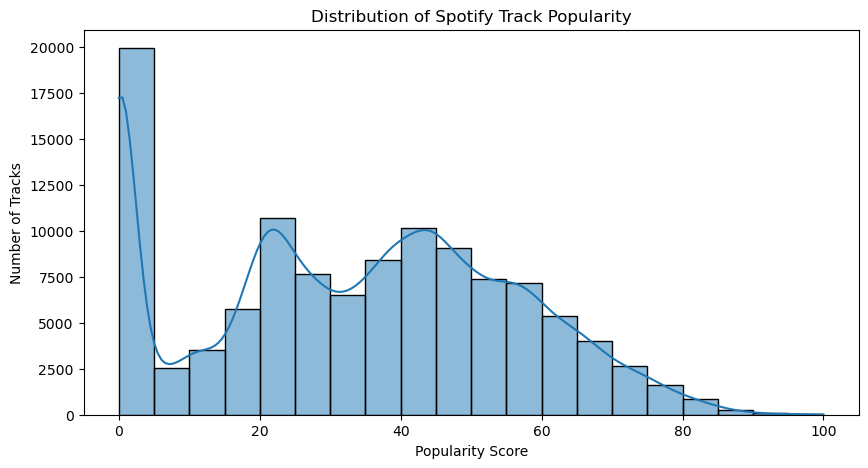

In [51]:
print(clean_data["duration_minutes"].describe())

plt.figure(figsize = (10,5))
sns.histplot(data = clean_data, x = "popularity", bins = 20, kde = True)
plt.title("Distribution of Spotify Track Popularity")
plt.xlabel("Popularity Score")
plt.ylabel("Number of Tracks")
#plt.tight_layout()
plt.show()

Most tracks have popularity scores between 20 and 60.

A large number of tracks have a popularity score of 0, which means they have very low or no recorded popularity in this dataset.

Only a small number of tracks have popularity scores above 80.

The average popularity is around 33.32, while the median is 35.

The distribution is uneven, with a large spike at zero and multiple peaks in other ranges.

### Distribution of Track Duration

count    113549.000000
mean          3.801356
std           1.773552
min           0.143100
25%           2.903067
50%           3.550000
75%           4.359800
max          87.288250
Name: duration_minutes, dtype: float64


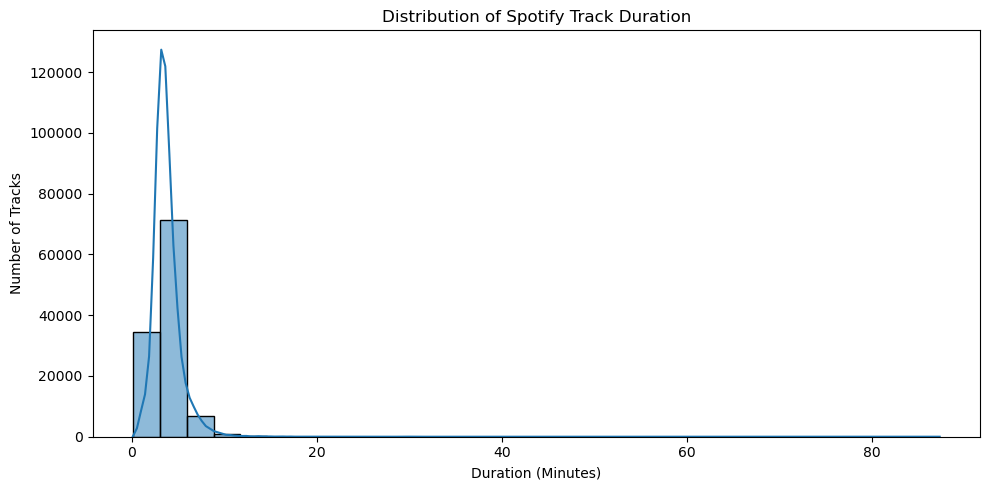

In [52]:
print(clean_data["duration_minutes"].describe())

plt.figure(figsize = (10,5))
sns.histplot(data = clean_data, x = "duration_minutes", bins = 30, kde = True)
plt.title("Distribution of Spotify Track Duration")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Tracks")
plt.tight_layout()
plt.show()

Most tracks are approximately 2–5 minutes long, with the highest concentration around 3–4 minutes.

The average track duration is approximately 3.80 minutes, and the median is 3.55 minutes.

The distribution is right-skewed, meaning most tracks are relatively short, while a small number of tracks are much longer.

A few tracks extend beyond 10 minutes, and the longest track is approximately 87.29 minutes.

These unusually long recordings stretch the chart and make the distribution of regular-length tracks harder to see.
    

### Distribution of Track Genres


In [53]:
# Count tracks by genre
genre_counts = clean_data["track_genre"].value_counts()
print("Top 10 most common genres:")
print(genre_counts.head(10))

Top 10 most common genres:
track_genre
acoustic       1000
emo            1000
rock-n-roll    1000
reggaeton      1000
disco          1000
r-n-b          1000
punk-rock      1000
pagode         1000
electronic     1000
mpb            1000
Name: count, dtype: int64


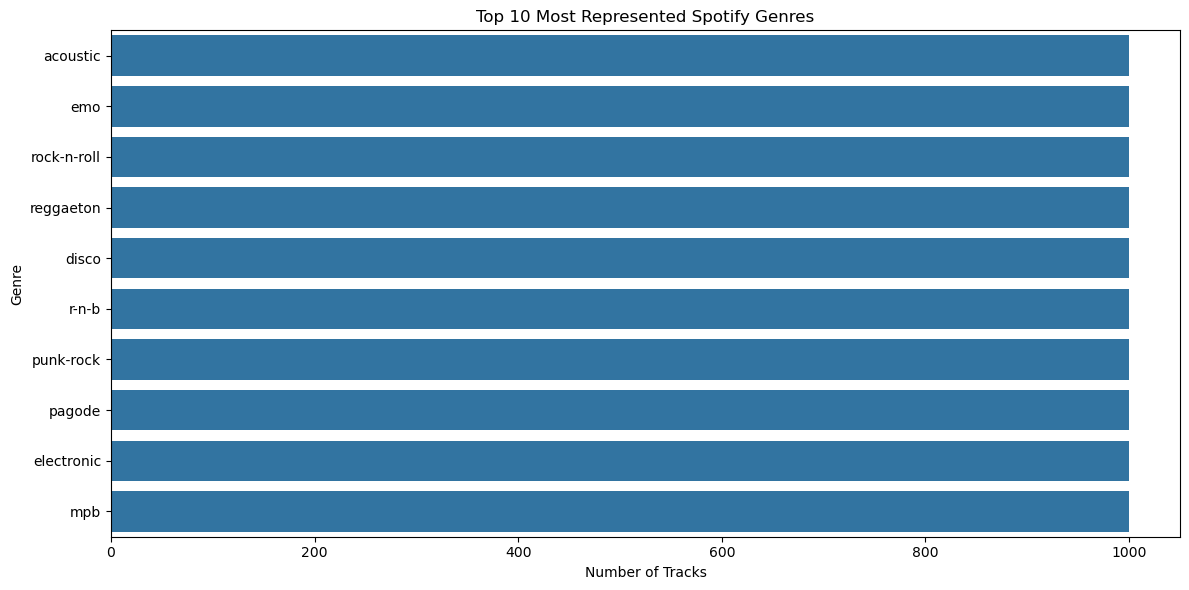

In [54]:
plt.figure(figsize=(12, 6))
sns.barplot(x = genre_counts.head(10).values, y = genre_counts.head(10).index)
plt.title("Top 10 Most Represented Spotify Genres")
plt.xlabel("Number of Tracks")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

All 10 genres have exactly 1,000 tracks. This tells us the dataset contains an equal number of tracks for each genre.

## Bivariate Analysis 

### Popularity by Genre
Top 10 genres by average popularity

In [55]:
genre_popularity = (clean_data.groupby("track_genre")["popularity"].mean().sort_values(ascending=False))
top_10_genres = genre_popularity.head(10)
top_10_genres

track_genre
pop-film     59.280280
k-pop        56.963928
chill        53.704705
sad          52.379000
grunge       49.582583
indian       49.528529
anime        48.766767
emo          48.128000
pop          47.903323
sertanejo    47.866000
Name: popularity, dtype: float64

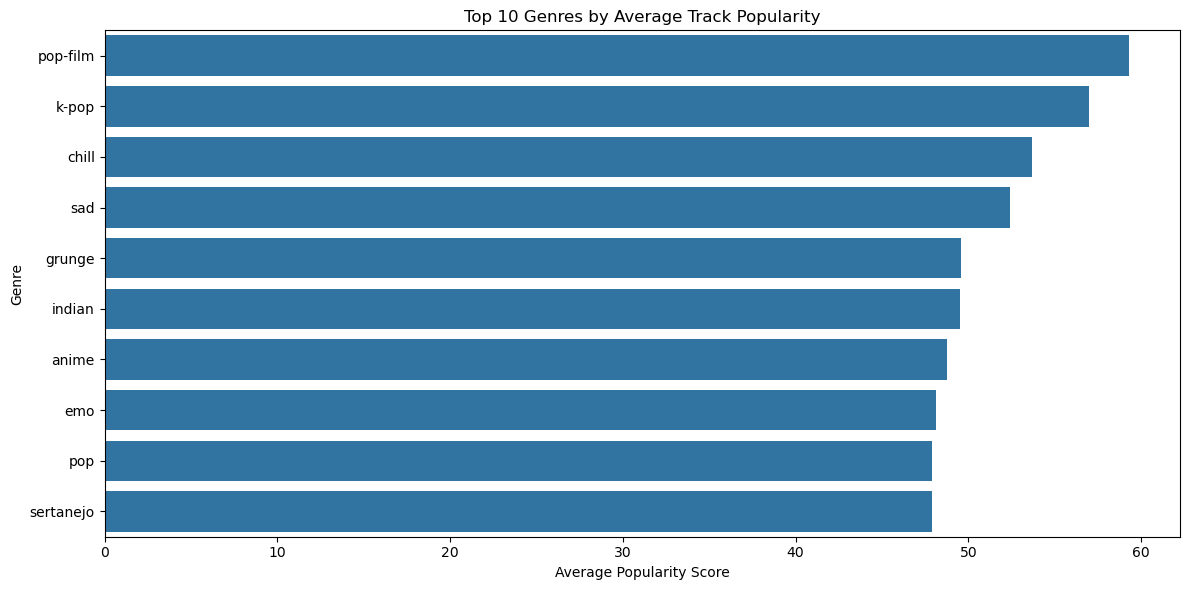

In [56]:
plt.figure(figsize=(12, 6))

sns.barplot(x=top_10_genres.values, y=top_10_genres.index)
plt.title("Top 10 Genres by Average Track Popularity")
plt.xlabel("Average Popularity Score")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

Pop-film has the highest average popularity score at approximately 59.28, followed by K-pop at 56.96.

Chill and sad genres also show relatively high average popularity scores of approximately 53.70 and 52.38, respectively.

Among the top 10 genres, Sertanejo has the lowest average popularity score at approximately 47.87.

The results show that average popularity differs across genres, which may help Spotify understand listener preferences.

## Scatter Plot

### Danceability vs Popularity

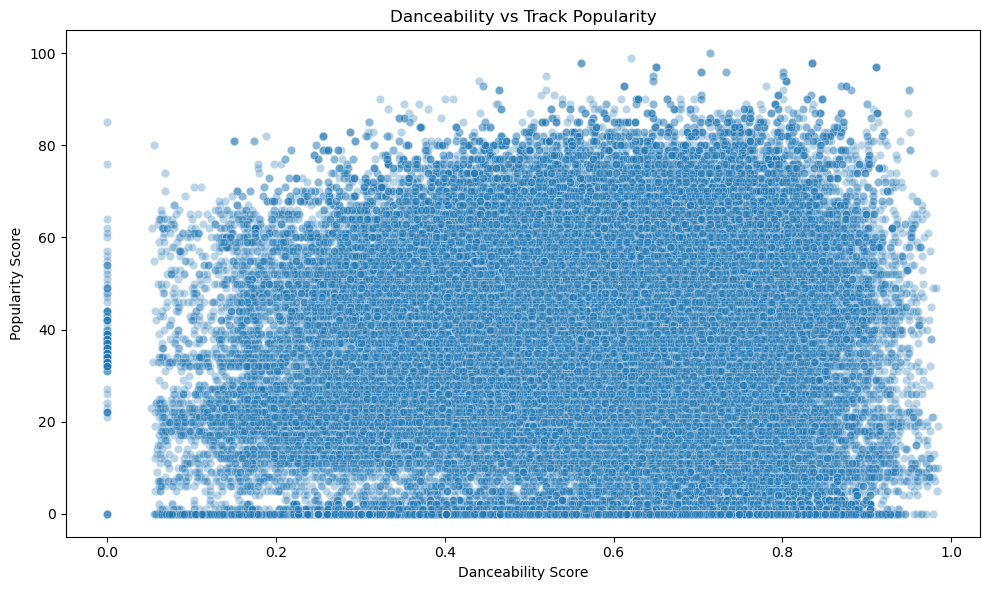

In [57]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=clean_data, x="danceability", y="popularity",  alpha=0.3)
plt.title("Danceability vs Track Popularity")
plt.xlabel("Danceability Score")
plt.ylabel("Popularity Score")
plt.tight_layout()
plt.show()

The chart shows that tracks with different danceability scores can have both low and high popularity.

Most tracks are spread across a wide range of popularity scores, regardless of their danceability.

There is no strong, clear relationship visible between danceability and popularity from this scatter plot alone.

This suggests that danceability by itself may not be enough to explain a track's popularity. Other factors, such as genre, artist, release date, and listener preferences, may also play a role.

### Energy vs Popularity

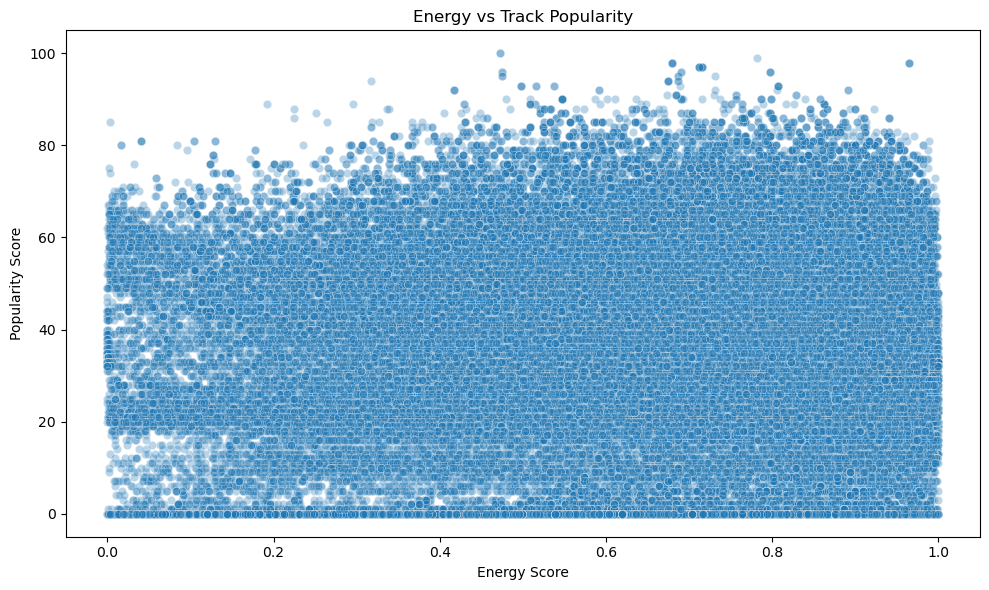

In [58]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=clean_data,x="energy", y="popularity", alpha=0.3)
plt.title("Energy vs Track Popularity")
plt.xlabel("Energy Score")
plt.ylabel("Popularity Score")

plt.tight_layout()
plt.show()

Tracks with both low and high energy levels appear across a wide range of popularity scores.

Some high-energy tracks are very popular, but many have low popularity as well.

Similarly, low-energy tracks can also achieve relatively high popularity.

The scatter plot does not show a strong, clear relationship between energy and popularity.

This suggests that energy alone may not explain a track's popularity. Other factors may also influence listener interest.

## Correlation Analysis

Correlation heatmap to examine how multiple audio features relate to popularity

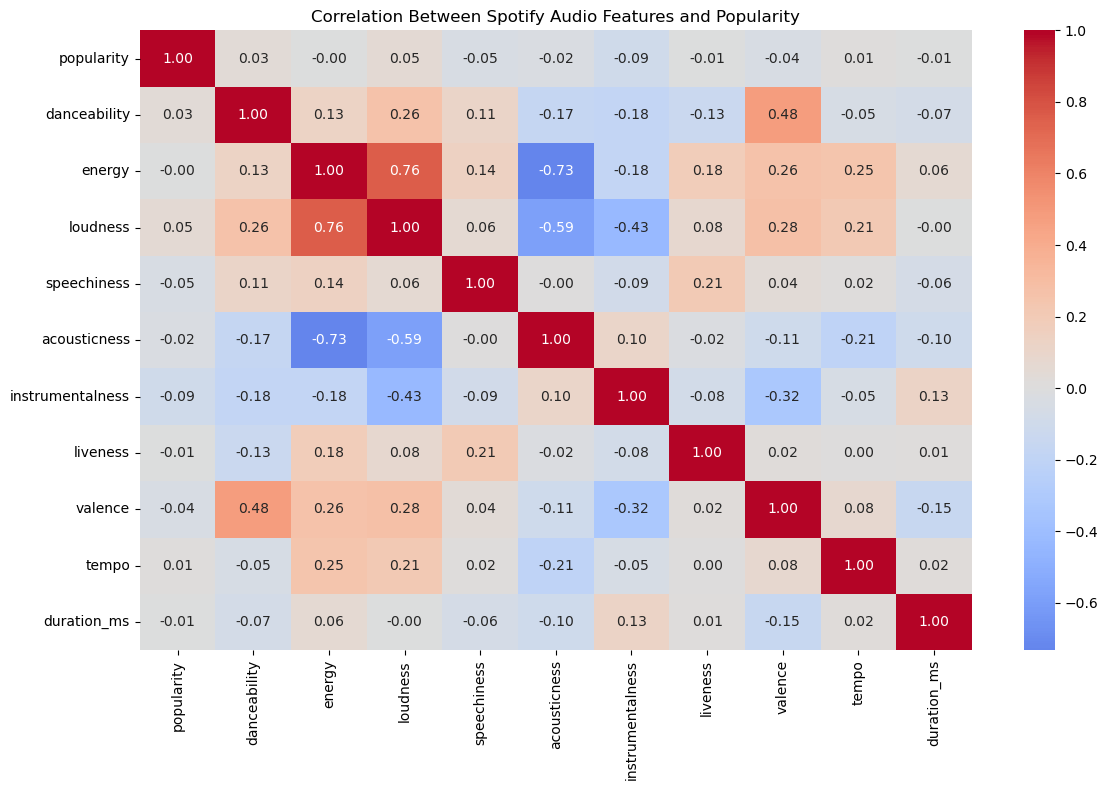

In [59]:
correlation_columns = [
    "popularity",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duration_ms"
]

correlation_matrix = clean_data[correlation_columns].corr()

plt.figure(figsize=(12, 8))
sns.heatmap( correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)

plt.title("Correlation Between Spotify Audio Features and Popularity")
plt.tight_layout()
plt.show()

The heatmap shows that some audio features are strongly related to each other, especially energy, loudness, and acousticness. 

However, most audio features have very weak correlations with track popularity.

This suggests that popularity may depend on other factors, such as artist recognition, marketing, release timing, listener preferences, and playlist exposure, which are not fully captured by these audio features.

# Business Questions and Analysis

### Which music genres have the highest average popularity?

In [60]:
genre_popularity = ( clean_data.groupby("track_genre")["popularity"].mean().sort_values(ascending=False))
genre_popularity.head(10)

track_genre
pop-film     59.280280
k-pop        56.963928
chill        53.704705
sad          52.379000
grunge       49.582583
indian       49.528529
anime        48.766767
emo          48.128000
pop          47.903323
sertanejo    47.866000
Name: popularity, dtype: float64

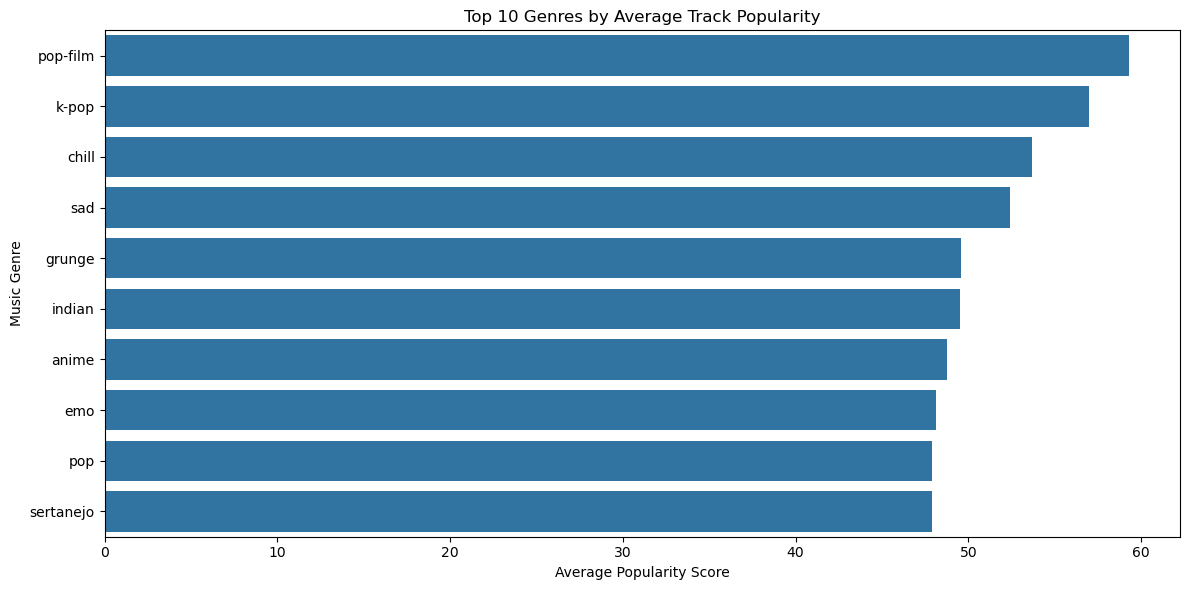

In [61]:
plt.figure(figsize=(12, 6))
sns.barplot(x=genre_popularity.head(10).values, y=genre_popularity.head(10).index)

plt.title("Top 10 Genres by Average Track Popularity")
plt.xlabel("Average Popularity Score")
plt.ylabel("Music Genre")
plt.tight_layout()
plt.show()

Business Insights:

Pop-film has the highest average popularity score among the genres in this dataset, followed by K-pop and Chill.

These results suggest that tracks in these genres may be worth exploring for content promotion and playlist placement.

However, average popularity alone does not prove that a genre will perform well for every audience.

Spotify should also consider listener preferences, regional trends, artist popularity, and the number of tracks available in each genre before making promotion decisions.

### Which genres have the highest number of tracks?

Business Insight:

The top 10 genres have approximately the same number of tracks in this dataset.

This suggests that the dataset has a relatively balanced representation of genres by track count.

However, having more tracks in a genre does not necessarily mean that listeners prefer that genre.

A music platform should compare genre counts with average popularity and actual listening activity before deciding which genres deserve more promotion.



### Which audio features are most strongly related to track popularity?

In [62]:
audio_features = [
    "popularity",
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "duration_ms"
]


popularity_correlation = (clean_data[audio_features].corr()["popularity"].drop("popularity").sort_values(ascending=False))
popularity_correlation

loudness            0.047368
danceability        0.034407
tempo               0.012187
energy             -0.002447
liveness           -0.005668
duration_ms        -0.007928
acousticness       -0.022356
valence            -0.041097
speechiness        -0.045463
instrumentalness   -0.094718
Name: popularity, dtype: float64

plt.figure(figsize=(10, 6))
sns.barplot(x=popularity_correlation.values, y=popularity_correlation.index)

plt.axvline(x=0, color="black", linestyle="--")
plt.title("Correlation of Audio Features with Track Popularity")
plt.xlabel("Correlation with Popularity")
plt.ylabel("Audio Feature")
plt.tight_layout()
plt.show()

Loudness has the highest positive correlation with track popularity, at approximately 0.047, but this relationship is extremely weak.

Instrumentalness has the strongest negative correlation, at approximately -0.095.

Overall, none of the audio features shows a strong linear relationship with popularity.

Therefore, audio features alone may not be sufficient to explain track popularity. Other factors, such as artist recognition, marketing, playlist placement, and listener preferences, may also matter.

### Do explicit tracks have higher popularity than non-explicit tracks?
Does the explicit-content label have any relationship with average track popularity?

In [63]:

explicit_popularity = (clean_data.groupby("explicit")["popularity"].agg(["mean", "median", "count"]))
explicit_popularity

,mean,median,count
explicit,,,
False,33.024896,34.0,103831
True,36.524799,37.5,9718


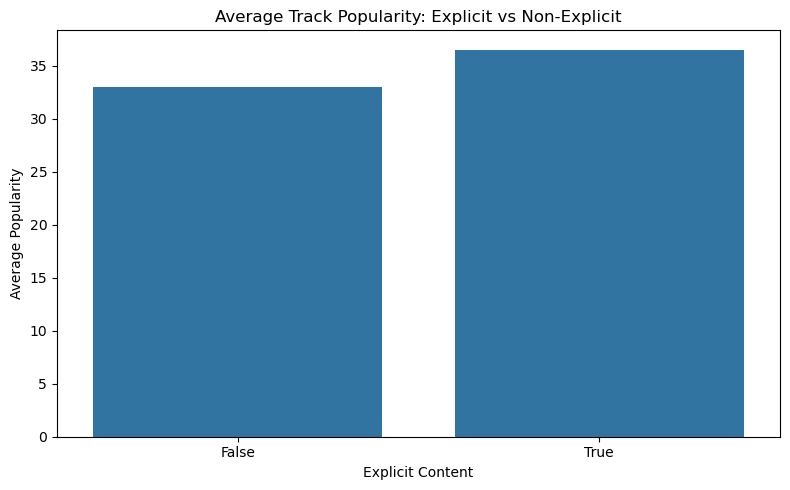

In [64]:
plt.figure(figsize=(8, 5))

sns.barplot(data=clean_data, x="explicit", y="popularity", errorbar=None)
plt.title("Average Track Popularity: Explicit vs Non-Explicit")
plt.xlabel("Explicit Content")
plt.ylabel("Average Popularity")
plt.tight_layout()
plt.show()

Business Insight: Explicit vs Non-Explicit Tracks

Explicit tracks have a higher average popularity score (36.52) than non-explicit tracks (33.02).

The median popularity is also higher for explicit tracks (37.5 versus 34).

However, the dataset contains far fewer explicit tracks than non-explicit tracks.

Music platforms should not assume that explicit tracks will always perform better. Genre, audience preferences, and other factors should also be considered.



### Do shorter or longer tracks tend to have higher popularity scores?

In [65]:
duration_bins = [0, 2, 3, 4, 5, float("inf")]

duration_labels = ["0–2 minutes", "2–3 minutes", "3–4 minutes", "4–5 minutes", "Over 5 minutes"]

clean_data["duration_category"] = pd.cut(clean_data["duration_minutes"],bins=duration_bins,labels=duration_labels, right=True, include_lowest=True)

duration_popularity = (clean_data.groupby("duration_category", observed=True)["popularity"].agg(["mean", "median", "count"]))

duration_popularity


,mean,median,count
duration_category,,,
0–2 minutes,28.623133,26.0,6225
2–3 minutes,32.215016,33.0,26012
3–4 minutes,34.751663,37.0,42249
4–5 minutes,34.775890,37.0,22779
Over 5 minutes,31.160464,31.0,16284


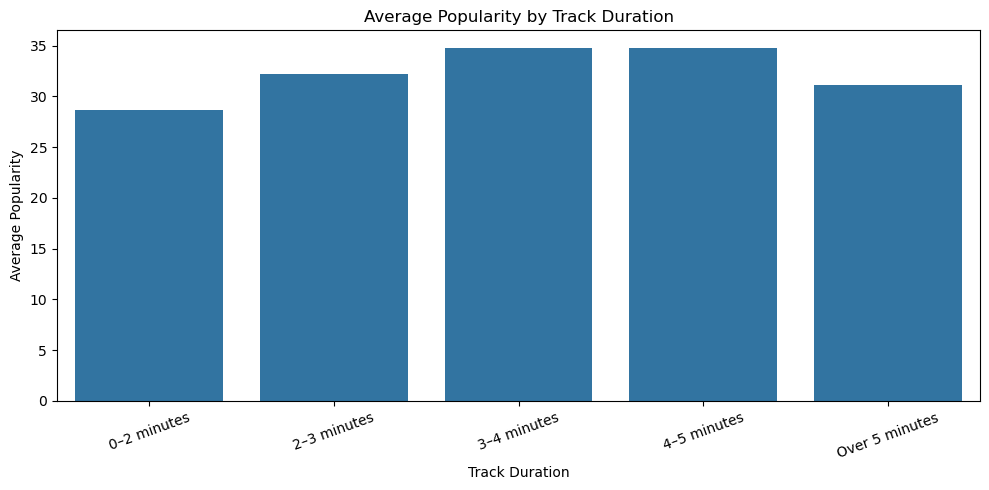

In [66]:
plt.figure(figsize=(10, 5))

sns.barplot(data=clean_data, x="duration_category", y="popularity", errorbar=None)
plt.title("Average Popularity by Track Duration")
plt.xlabel("Track Duration")
plt.ylabel("Average Popularity")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Tracks with a duration of 3–5 minutes have the highest average popularity, with scores around 34.75.

Tracks shorter than 2 minutes have the lowest average popularity, around 28.62.

Tracks longer than 5 minutes have an average popularity of approximately 31.16.

This suggests that medium-length tracks perform slightly better in terms of average popularity in this dataset.

### Which artists have the most popular tracks on average?
Identify artists whose tracks have high average popularity, considering only artists with at least 10 tracks in the dataset. This helps avoid ranking an artist based on just one or two tracks.

In [67]:
artist_popularity = (clean_data.groupby("artists").agg(average_popularity=("popularity", "mean"),total_tracks=("track_id", "count")))

artist_popularity = artist_popularity[artist_popularity["total_tracks"] >= 10]

top_artists = artist_popularity.sort_values(by="average_popularity", ascending=False).head(10)
top_artists

,average_popularity,total_tracks
artists,,
Bad Bunny,87.083333,48
Marshmello;Khalid,84.000000,10
Måneskin,83.666667,12
Ariana Grande,81.454545,11
Clairo,77.000000,10
Farruko,76.692308,13
Radiohead,76.650000,20
Travis Scott,76.277778,18
Labrinth,76.083333,12


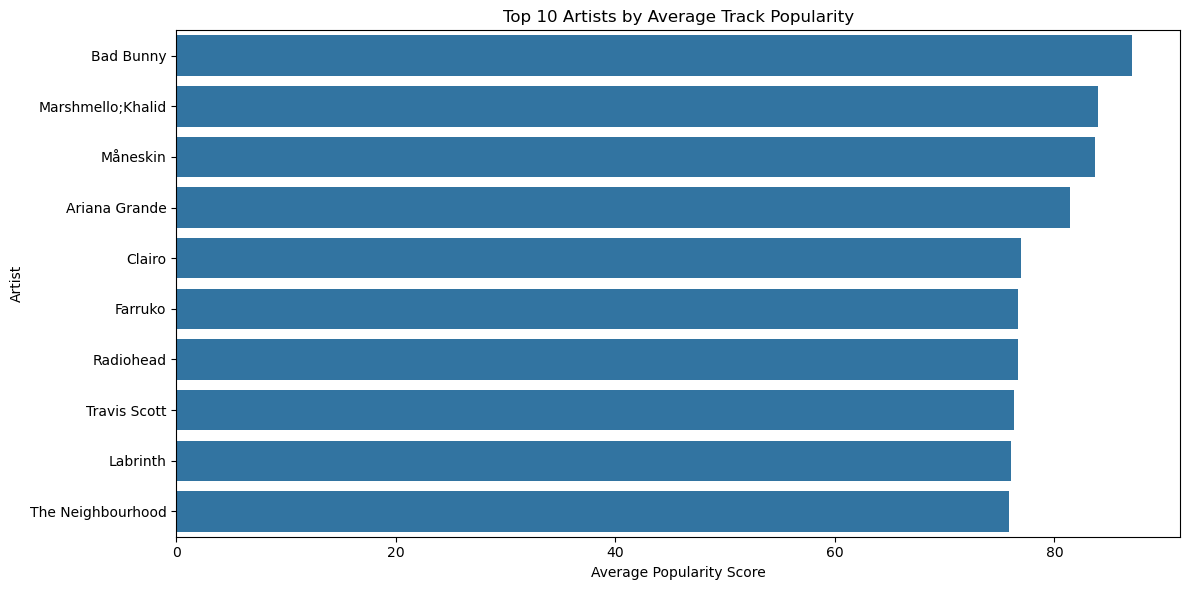

In [68]:
plt.figure(figsize=(12, 6))
sns.barplot(data=top_artists.reset_index(), x="average_popularity", y="artists")

plt.title("Top 10 Artists by Average Track Popularity")
plt.xlabel("Average Popularity Score")
plt.ylabel("Artist")
plt.tight_layout()
plt.show()

Key Findings
1. Genre popularity: Pop-film has the highest average popularity score at approximately 59.28, followed by K-pop at 56.96. This suggests that these genres perform well in terms of average popularity in this dataset.
2. Track duration: Tracks lasting 3–5 minutes have the highest average popularity, around 34.75. Very short tracks (0–2 minutes) and tracks longer than 5 minutes have lower average popularity.
3. Audio features: Loudness has the strongest positive correlation with popularity (approximately 0.047), followed by danceability (0.034). However, these relationships are very weak, so audio features alone do not explain track popularity.
4. Explicit content: Explicit tracks have a higher average popularity score (36.52) than non-explicit tracks (33.02). However, this difference does not prove that explicit content causes higher popularity.
5. Artist popularity: Bad Bunny has the highest average popularity score (87.08) among the artists shown, considering only artists with at least 10 tracks in the dataset.
6. Genre representation: The top 10 genres shown in your chart each contain around 1,000 tracks. This indicates that the dataset has a balanced number of records across these genres, although it does not mean that they are equally popular.
7. Overall pattern: Popularity varies considerably across tracks. No single audio feature appears to have a strong linear relationship with popularity, suggesting that other factors—such as artist recognition, release date, promotion, and listener preferences may also matter.

# Overall Conclusion
The analysis shows that track popularity varies by genre, artist, duration, and explicit-content status. Pop-film and K-pop have high average popularity scores, while tracks lasting 3–5 minutes perform relatively well in this dataset. However, the correlation analysis shows that individual audio features have only weak relationships with popularity. Therefore, Spotify popularity cannot be explained by audio characteristics alone. These findings can help guide further analysis of genre trends, artist performance, and listener preferences, but they should be treated as patterns in the dataset rather than proof of what causes a track to become popular.

# Key Findings

Genre popularity: Pop-film and K-pop have the highest average popularity scores among the genres analyzed.

Track duration: Tracks between 3 and 5 minutes have higher average popularity than very short tracks or tracks longer than 5 minutes.

Audio features: Loudness and danceability show weak positive relationships with popularity. Other audio features have weak negative or almost no linear relationships.

Explicit content: Explicit tracks have a higher average popularity score than non-explicit tracks in this dataset.

Artist performance: Bad Bunny has the highest average popularity score among the artists included in the analysis.

Popularity variation: Track popularity varies widely, and no single audio feature can explain why a track becomes popular.

Business insight: Genre, artist recognition, listener preferences, and other factors may influence popularity. Further analysis is needed to understand these relationships.

# Business Recommendations

- **Focus on popular genres:** Spotify can analyze genres such as pop-film and K-pop to understand listener preferences and improve personalized music recommendations.

- **Consider track duration:** Since tracks between 3 and 5 minutes have higher average popularity in this dataset, artists can study this duration range when planning new releases. However, duration alone does not guarantee success.

- **Improve recommendation systems:** Spotify should consider multiple factors, including genre, artist, listening history, and audio features, rather than relying on a single feature to recommend songs.

- **Support emerging artists:** Spotify can identify artists and genres gaining popularity and provide more opportunities for emerging musicians to reach their target audiences.

- **Analyze explicit-content preferences:** The difference in average popularity between explicit and non-explicit tracks can help Spotify understand audience preferences across different listener groups.

- **Use multiple performance indicators:** Music teams should consider popularity scores along with actual streams, saves, playlist additions, and listener engagement to evaluate track performance more effectively.

- **Perform continuous analysis:** Spotify should regularly analyze changing music trends because listener preferences and popular genres can change over time.

# Limitations

- **Dataset limitations:** The analysis is based on the available Spotify Tracks Dataset, so the findings may not represent every song or listener on Spotify.

- **Popularity score:** The popularity score does not represent lifetime streams directly. It may be influenced by factors such as recent listening activity and other platform-specific factors.

- **Correlation does not mean causation:** Although some audio features show relationships with popularity, we cannot conclude that these features directly cause a track to become popular.

- **Missing business information:** The dataset does not include detailed information about marketing campaigns, playlist placements, listener demographics, or promotional activities.

- **Time-related limitations:** Music trends change over time. The analysis may not reflect current listener preferences because popularity and genre trends can change.

- **Genre representation:** Some genres may have different levels of representation in the dataset, which can affect comparisons between genres.

- **Limited analysis methods:** This project mainly uses descriptive statistics and exploratory data analysis. More advanced statistical tests and predictive models could provide additional insights.

- **Artist comparison:** Artists with different numbers of tracks in the dataset may not be directly comparable, even when a minimum track-count threshold is applied.

# Conclusion

In this project, I analyzed the Spotify Tracks Dataset to understand music trends and the factors associated with track popularity.

- I started by understanding the dataset, checking data types, identifying missing values and duplicates, and cleaning the data for analysis.
- I performed univariate, bivariate, and multivariate analysis to explore track popularity, duration, genres, artists, and audio features.
- The analysis showed that pop-film and K-pop had the highest average popularity scores among the genres analyzed.
- Tracks between 3 and 5 minutes had relatively higher average popularity, while explicit tracks also showed a higher average popularity than non-explicit tracks.
- The correlation analysis revealed that audio features had only weak relationships with popularity, indicating that popularity cannot be explained by audio characteristics alone.
- Based on these findings, I suggested recommendations related to personalized music discovery, emerging artists, and continuous analysis of listener preferences.

Overall, this project helped me develop practical skills in Python, Pandas, data cleaning, exploratory data analysis, data visualization, and deriving business insights from data.

The findings can support further analysis of music trends and recommendation strategies. However, the results describe patterns in the available dataset and do not establish the direct causes of track popularity.

# Future Scope

- **Popularity Prediction:** Build a machine learning model to predict track popularity using audio features, genre, and artist information.

- **Music Recommendation System:** Develop a recommendation system that suggests songs based on users' listening preferences, favorite genres, and audio characteristics.

- **Time-Based Trend Analysis:** Analyze historical popularity data to understand how music trends change over time and identify emerging genres.

- **Advanced Genre Analysis:** Explore genre-specific patterns to understand which audio features are associated with popularity within different genres.

- **Artist Performance Analysis:** Compare artists based on popularity, track count, and other available performance indicators to identify emerging artists.

- **Listener Preference Analysis:** Use listener-level data, if available, to understand how preferences differ by age group, region, and listening habits.

- **Advanced Statistical Analysis:** Apply statistical tests to determine whether differences in popularity between explicit and non-explicit tracks or between duration groups are statistically significant.

- **Interactive Dashboard:** Develop a Power BI or Tableau dashboard to display genre trends, popularity distributions, artist comparisons, and audio-feature relationships interactively.

- **Additional Data Integration:** Combine this dataset with reliable data on streams, playlist placements, release dates, and listener engagement to gain a more complete understanding of track performance.

Overall, these improvements could extend the current exploratory analysis into a more advanced project involving predictive analytics, recommendation systems, and interactive business intelligence.